In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load dataset
df = pd.read_csv("Salary Data.csv")

# Remove rows with missing values
df = df.dropna()

# Feature and target
X = df[["Years of Experience"]]
y = df["Salary"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)
print(predictions)

FileNotFoundError: [Errno 2] No such file or directory: 'Salary Data.csv'

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Experience": X_test.values.flatten(), #flatten is used to return a copy of the array collapsed to 1D
    "Actual Salary": y_test.values,
    "Predicted Salary": predictions
})

print(results)



    Experience  Actual Salary  Predicted Salary
0         21.0       180000.0     174795.471295
1         10.0        65000.0      99746.979370
2         16.0       125000.0     140682.520420
3          6.0        80000.0      72456.618670
4         17.0       140000.0     147505.110595
..         ...            ...               ...
70         7.0        75000.0      79279.208845
71        11.0        90000.0     106569.569545
72         4.0        60000.0      58811.438320
73        14.0       140000.0     127037.340070
74         8.0       110000.0      86101.799020

[75 rows x 3 columns]


In [ ]:
experience = float(input("Enter Years of Experience: "))

predicted_salary = model.predict([[experience]])

print(f"\nFor Experience = {experience} years")
print(f"Predicted Salary = {predicted_salary[0]:.2f}")

Enter Years of Experience: 2

For Experience = 2.0 years
Predicted Salary = 45166.26


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


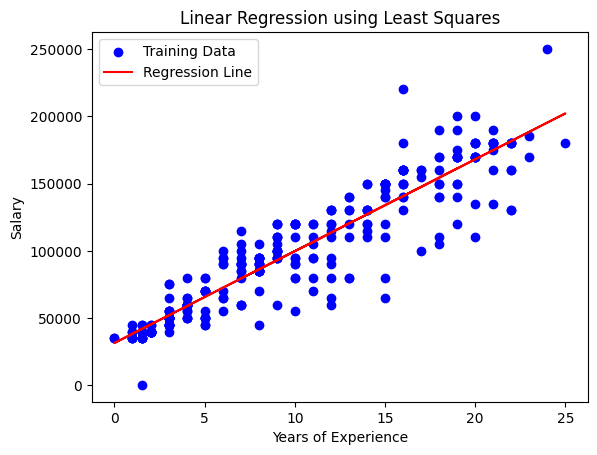

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X_train, y_train, color="blue", label="Training Data")
plt.plot(X_train, model.predict(X_train), color="red", label="Regression Line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression using Least Squares")
plt.legend()
plt.show()


In [ ]:
#USING 2 VARIABLES

In [ ]:
X = df[["Age", "Years of Experience"]]

# Target variable
y = df["Salary"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression() #y=(m1x1+m2x2) + c
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)

print("Predicted Salaries:")
print(predictions)

#Mean square root
mse = ((predictions - y_test) ** 2).mean()
rmse = mse ** 0.5
print("\nRoot Mean Squared Error:", rmse)



# Model parameters
print("\nCoefficient for Age:", model.coef_[0]) #m1
print("Coefficient for Years of Experience:", model.coef_[1]) #m2
print("Intercept:", model.intercept_) #c

Predicted Salaries:
[171912.18158604 103906.32190127 141242.01483791  74586.75295282
 142592.61263759 149258.1388261  181235.17196897  93276.46512361
  54590.17438729  94583.33151835 123902.9004668  174569.64578046
  37294.79142112  91925.86732393 133225.89084972  54590.17438729
  65263.76256989  37948.22461849  78594.81494691  85260.34113542
 101248.85770685  94583.33151835 143899.47903233  67921.22676431
  74586.75295282  55940.77218697 154573.06721493  42609.71980995
 118587.97207797 150608.73662577  46617.78180404 125253.49826648
  51932.71019287 137233.95284382 101248.85770685  23310.30584673
 169254.71739162  47924.64819878 146600.67463168  58598.23638138
  47924.64819878  94583.33151835 193259.35795125 163896.05759785
  42609.71980995 141242.01483791  99941.99131212  39952.25561553
  45267.18400437  42609.71980995 155923.66501461  82602.876941
 129217.82885563 114579.91008387  97240.79571276 114579.91008387
 198574.28634008  83909.74333574 171912.18158604  69271.82456399
 114579

In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r2 = r2_score(y_test, predictions)
print(f"R-squared Score: {r2:.4f}")

R-squared Score: 0.8885


### Comparing Model Performance (R-squared)

R-squared represents the proportion of variance for the dependent variable that's explained by an independent variable or variables in a regression model.

In [ ]:
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

# 1. Single Variable Model (Experience Only)
# We extract the 'Years of Experience' for the same training indices used in the multi-variable split
X_train_s = df.loc[y_train.index, ["Years of Experience"]]
X_test_s = df.loc[y_test.index, ["Years of Experience"]]

# Fit single variable model
model_single = LinearRegression()
model_single.fit(X_train_s, y_train)

# Predict and calculate R2 for single variable
preds_single = model_single.predict(X_test_s)
r2_single = r2_score(y_test, preds_single)

# 2. Multi-Variable Model (Age + Experience)
# 'r2' was already calculated for the multi-variable model in cell e4591e75

print(f"R-squared (Experience only): {r2_single:.4f}")
print(f"R-squared (Age + Experience): {r2:.4f}")

if r2 > r2_single:
    print(f"\nImprovement: Adding 'Age' increased the R-squared score by {r2 - r2_single:.4f}")
else:
    print("\nAdding 'Age' did not improve the R-squared score.")

R-squared (Experience only): 0.8991
R-squared (Age + Experience): 0.8885

Adding 'Age' did not improve the R-squared score.


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Calculations for Single Variable Model
mse_s = mean_squared_error(y_test, preds_single)
rmse_s = np.sqrt(mse_s)
mae_s = mean_absolute_error(y_test, preds_single)

# Calculations for Multi-Variable Model
mse_m = mean_squared_error(y_test, predictions)
rmse_m = np.sqrt(mse_m)
mae_m = mean_absolute_error(y_test, predictions)

print("--- Single Variable Error (Experience) ---")
print(f"RMSE: ${rmse_s:,.2f}")
print(f"MAE:  ${mae_s:,.2f}")

print("\n--- Multi-Variable Error (Age + Experience) ---")
print(f"RMSE: ${rmse_m:,.2f}")
print(f"MAE:  ${mae_m:,.2f}")

In [ ]:
results = pd.DataFrame({
    "Age": X_test["Age"].values,
    "Years of Experience": X_test["Years of Experience"].values,
    "Actual Salary": y_test.values,
    "Predicted Salary": predictions
})

print(results)

     Age  Years of Experience  Actual Salary  Predicted Salary
0   48.0                 21.0       180000.0     171912.181586
1   39.0                 10.0        65000.0     103906.321901
2   44.0                 16.0       125000.0     141242.014838
3   34.0                  6.0        80000.0      74586.752953
4   43.0                 17.0       140000.0     142592.612638
..   ...                  ...            ...               ...
70  33.0                  7.0        75000.0      75937.350752
71  41.0                 11.0        90000.0     113229.312284
72  33.0                  4.0        60000.0      63913.164770
73  45.0                 14.0       140000.0     135883.355044
74  36.0                  8.0       110000.0      87917.805330

[75 rows x 4 columns]


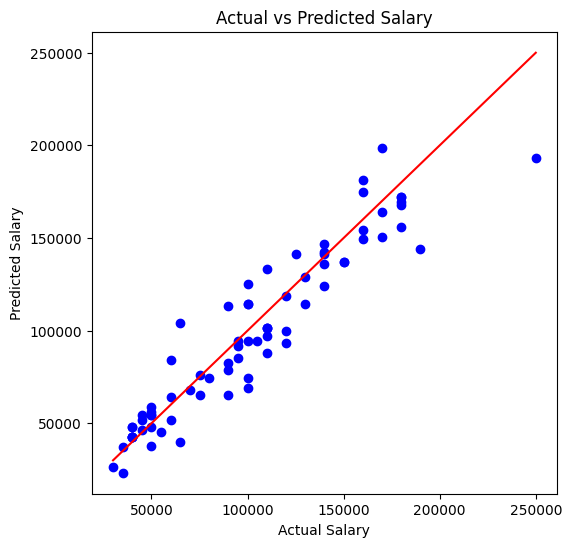

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, predictions, color="blue")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

In [ ]:
age = float(input("Enter Age: "))
experience = float(input("Enter Years of Experience: "))

predicted_salary = model.predict([[age, experience]])

#mean square root
mse = ((predicted_salary - y_test) ** 2).mean()
rmse = mse ** 0.5
print("\nRoot Mean Squared Error:", rmse)

print(f"\nFor Age = {age} and Experience = {experience} years")
print(f"Predicted Salary = {predicted_salary[0]:.2f}")


Enter Age: 34
Enter Years of Experience: 3

Root Mean Squared Error: 63165.80874793578

For Age = 34.0 and Experience = 3.0 years
Predicted Salary = 62562.57


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
